In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sys
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, auc, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error, median_absolute_error)

# ==========================================
# 1. PREPARAÇÃO DOS DADOS E IMPORTAÇÕES
# ==========================================
sys.path.append('../src')
from expert_system import MotorInferencia

# Classificação
df_class = pd.read_csv('../data/processed/dataset_classification.csv')
X_class = df_class.drop(columns=['TARGET'])
y_class = df_class['TARGET']
_, X_test_c, _, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)

# Regressão
df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
X_reg = df_reg.drop(columns=['TARGET'])
y_reg = df_reg['TARGET']
_, X_test_r, _, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Carregar os Modelos Treinados (só vai funcionar quando o NB 05 terminar)
best_tree_c = joblib.load('../data/processed/best_tree_c.pkl')
best_rf_c = joblib.load('../data/processed/best_rf_c.pkl')
best_gb_c = joblib.load('../data/processed/best_gb_c.pkl')

best_tree_r = joblib.load('../data/processed/best_tree_r.pkl')
best_rf_r = joblib.load('../data/processed/best_rf_r.pkl')
best_gb_r = joblib.load('../data/processed/best_gb_r.pkl')

# 1. Métricas de Classificação

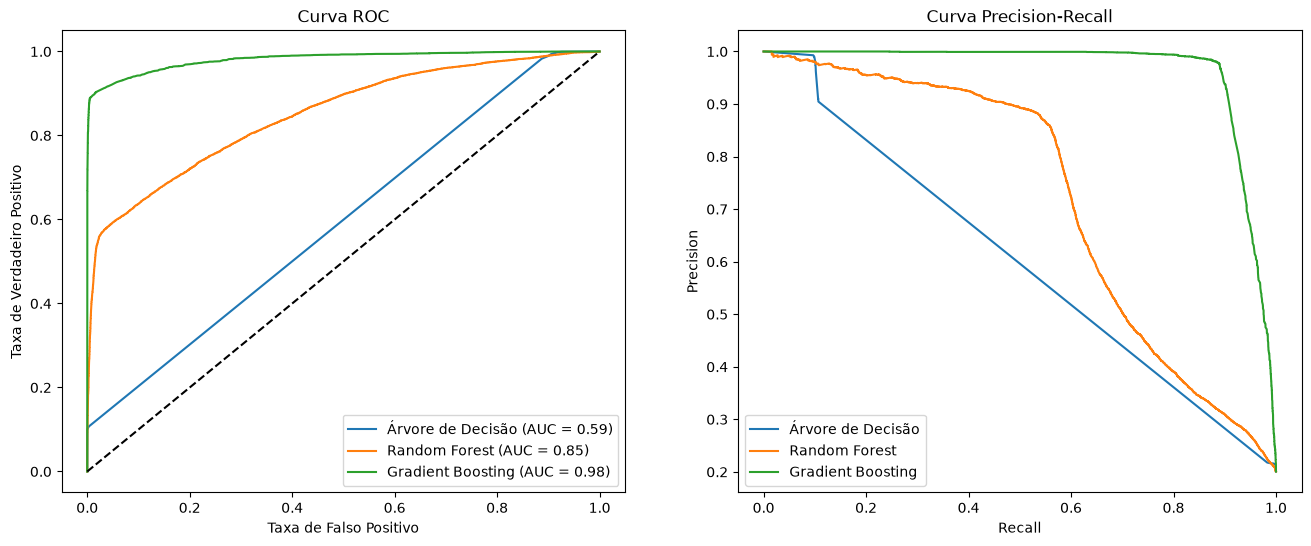

In [2]:
modelos_c = {
    'Sistema Especialista': MotorInferencia(tipo='classificacao'),
    'Árvore de Decisão': best_tree_c,
    'Random Forest': best_rf_c,
    'Gradient Boosting': best_gb_c
}

resultados_c = []
plt.figure(figsize=(16, 6))

for nome, modelo in modelos_c.items():
    if nome == 'Sistema Especialista':
        y_pred = modelo.prever(X_test_c)
        y_prob = None
    else:
        y_pred = modelo.predict(X_test_c)
        y_prob = modelo.predict_proba(X_test_c)[:, 1]
    
    acc = accuracy_score(y_test_c, y_pred)
    prec = precision_score(y_test_c, y_pred, zero_division=0)
    rec = recall_score(y_test_c, y_pred, zero_division=0)
    f1 = f1_score(y_test_c, y_pred, zero_division=0)
    
    roc_auc = roc_auc_score(y_test_c, y_prob) if y_prob is not None else np.nan
    
    resultados_c.append({'Modelo': nome, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'ROC-AUC': roc_auc})
    
    # Gerando Curvas ROC e PR apenas para modelos com probabilidade[cite: 26]
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_test_c, y_prob)
        plt.subplot(1, 2, 1)
        plt.plot(fpr, tpr, label=f'{nome} (AUC = {roc_auc:.2f})')
        
        prec_curve, rec_curve, _ = precision_recall_curve(y_test_c, y_prob)
        plt.subplot(1, 2, 2)
        plt.plot(rec_curve, prec_curve, label=nome)

# Ajustes dos Gráficos ROC e PR
plt.subplot(1, 2, 1)
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curva ROC')
plt.xlabel('Taxa de Falso Positivo')
plt.ylabel('Taxa de Verdadeiro Positivo')
plt.legend()

plt.subplot(1, 2, 2)
plt.title('Curva Precision-Recall')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.savefig('../reports/figures/roc_pr_curves.png', bbox_inches='tight')
plt.show()

# 2. Justificativa Do Sistema Especialista

In [3]:
print("\n[JUSTIFICATIVA P/ RELATÓRIO]: Como obter probabilidades no Sistema Especialista?")
print("O Sistema Especialista construído opera com regras binárias determinísticas (saída 0 ou 1). Por não ser um modelo probabilístico, é impossível traçar Curvas ROC ou PR de forma nativa. Para obter probabilidades, seria necessário implementar Fatores de Certeza (Certainty Factors) ou Lógica Fuzzy no motor de inferência, atribuindo pesos a cada regra.")


[JUSTIFICATIVA P/ RELATÓRIO]: Como obter probabilidades no Sistema Especialista?
O Sistema Especialista construído opera com regras binárias determinísticas (saída 0 ou 1). Por não ser um modelo probabilístico, é impossível traçar Curvas ROC ou PR de forma nativa. Para obter probabilidades, seria necessário implementar Fatores de Certeza (Certainty Factors) ou Lógica Fuzzy no motor de inferência, atribuindo pesos a cada regra.


# 3. Métricas de Regressão e Resíduos

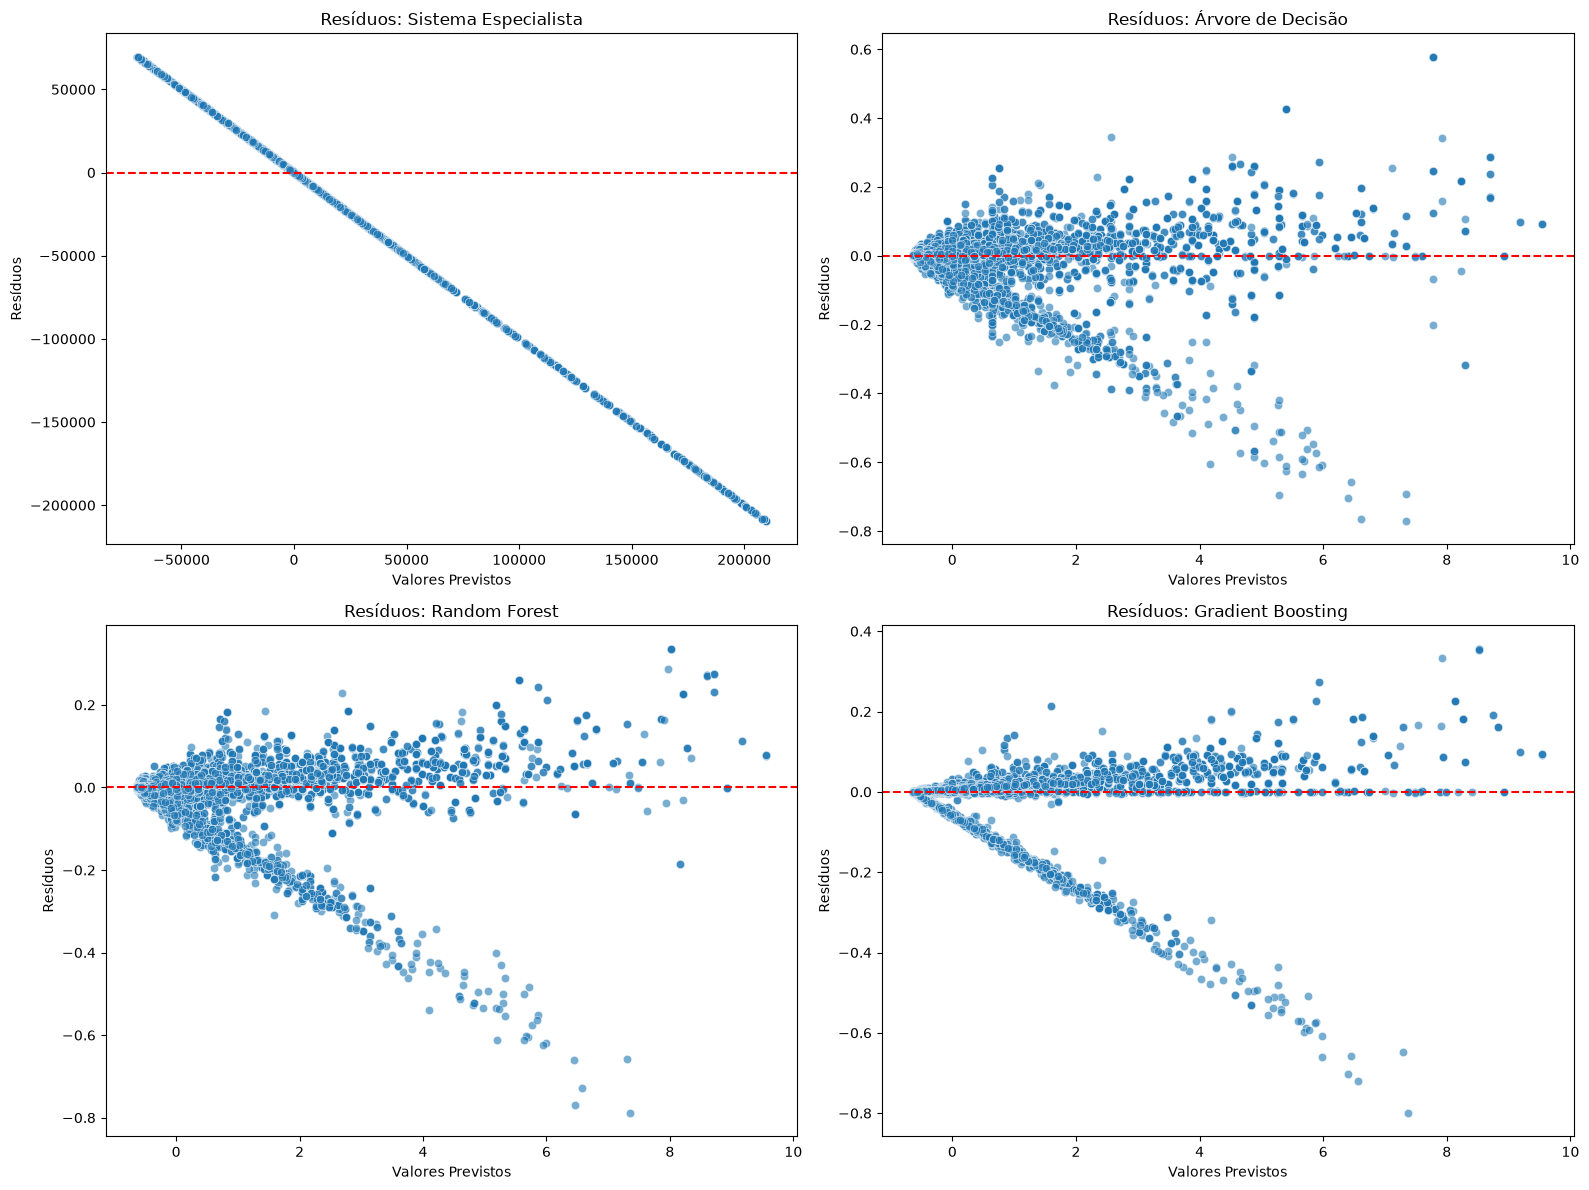

In [4]:
modelos_r = {
    'Sistema Especialista': MotorInferencia(tipo='regressao'),
    'Árvore de Decisão': best_tree_r,
    'Random Forest': best_rf_r,
    'Gradient Boosting': best_gb_r
}

resultados_r = []
plt.figure(figsize=(16, 12))

for i, (nome, modelo) in enumerate(modelos_r.items(), 1):
    if nome == 'Sistema Especialista':
        y_pred = modelo.prever(X_test_r)
    else:
        y_pred = modelo.predict(X_test_r)
        
    mae = mean_absolute_error(y_test_r, y_pred)
    mse = mean_squared_error(y_test_r, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_test_r, y_pred)
    r2 = r2_score(y_test_r, y_pred)
    medae = median_absolute_error(y_test_r, y_pred)
    
    resultados_r.append({'Modelo': nome, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'MAPE': mape, 'R2': r2, 'MedAE': medae})
    
    # Gráfico de Resíduos[cite: 26]
    residuos = y_test_r - y_pred
    plt.subplot(2, 2, i)
    sns.scatterplot(x=y_pred, y=residuos, alpha=0.6)
    plt.axhline(0, color='red', linestyle='--')
    plt.title(f'Resíduos: {nome}')
    plt.xlabel('Valores Previstos')
    plt.ylabel('Resíduos')

plt.tight_layout()
plt.savefig('../reports/figures/residuos_regressao.png', bbox_inches='tight')
plt.show()

# 4. Exportar Tabelas de Resultados

In [7]:
df_res_c = pd.DataFrame(resultados_c)
df_res_r = pd.DataFrame(resultados_r)

df_res_c.to_csv('../reports/tables/metricas_classificacao.csv', index=False)
df_res_r.to_csv('../reports/tables/metricas_regressao.csv', index=False)

print("\n--- Tabela de Métricas: Classificação ---")
display(df_res_c)
print("\n--- Tabela de Métricas: Regressão ---")
display(df_res_r)
print("\nEtapa 5 concluída! Gráficos salvos na pasta reports/figures/ e tabelas em reports/tables/")


--- Tabela de Métricas: Classificação ---


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Sistema Especialista,0.20864,0.201146,0.990136,0.334365,NaN
1,Árvore de Decisão,0.81904,0.974113,0.101225,0.183394,0.594736
2,Random Forest,0.80134,1.000000,0.010362,0.020511,0.850331
3,Gradient Boosting,0.94654,0.996360,0.736375,0.846863,0.981648



--- Tabela de Métricas: Regressão ---


,Modelo,MAE,MSE,RMSE,MAPE,R2,MedAE
0,Sistema Especialista,15573.796840,9.432960e+08,30713.124011,106860.114969,-9.511541e+08,4733.989706
1,Árvore de Decisão,0.016542,1.708091e-03,0.041329,0.129836,9.982777e-01,0.005307
2,Random Forest,0.014599,1.467396e-03,0.038307,0.108984,9.985204e-01,0.004312
3,Gradient Boosting,0.011914,1.326500e-03,0.036421,0.077786,9.986624e-01,0.002471



Etapa 5 concluída! Gráficos salvos na pasta reports/figures/ e tabelas em reports/tables/
